In [1]:
from pathlib import Path
import csv
import math
import struct

import dpkt
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN, KMeans, SpectralClustering
import hdbscan


# Define static variables

In [2]:
PCAP_PATH = Path("../data/driveway.pcap")


CALIBRATION_PATH = Path("../Lidar setup/JT128_angle_correction.csv")
if not CALIBRATION_PATH.exists():
    CALIBRATION_PATH = Path("Lidar setup/JT128_angle_correction.csv")


MIN_FRAMES  = 70
MAX_FRAMES = 100


## Filtering, subsampling, and clustering

In [3]:
def prepare_points(points, min_distance, max_distance, keep_fraction, seed):
    distances = np.linalg.norm(points, axis=1)
    filtered = points[(distances >= min_distance) & (distances <= max_distance)]
    if len(filtered) and keep_fraction < 1.0:
        keep_count = max(1, int(np.ceil(len(filtered) * keep_fraction)))
        rng = np.random.default_rng(seed)
        indices = np.sort(rng.choice(len(filtered), size=keep_count, replace=False))
        filtered = filtered[indices]
    return filtered


def remove_ground_plane(points, distance_threshold, max_iterations, max_tilt_degrees, seed):
    if distance_threshold <= 0 or not np.isfinite(distance_threshold):
        raise ValueError("Ground distance threshold must be a finite positive value.")
    if isinstance(max_iterations, bool) or not isinstance(max_iterations, int) or max_iterations < 1:
        raise ValueError("Ground RANSAC iterations must be a positive integer.")
    if not 0 < max_tilt_degrees < 90:
        raise ValueError("Maximum ground tilt must be between 0 and 90 degrees.")
    if len(points) < 3:
        return points, 0

    candidate_count = min(len(points), max(3, int(np.ceil(len(points) * 0.35))))
    candidate_indices = np.argsort(points[:, 2])[:candidate_count]
    candidates = points[candidate_indices]
    rng = np.random.default_rng(seed)
    minimum_vertical_normal = np.cos(np.deg2rad(max_tilt_degrees))
    best_inliers = None
    best_count = 0

    for _ in range(max_iterations):
        sample = candidates[rng.choice(len(candidates), size=3, replace=False)]
        normal = np.cross(sample[1] - sample[0], sample[2] - sample[0])
        normal_length = np.linalg.norm(normal)
        if normal_length <= 1e-12:
            continue
        normal /= normal_length
        if normal[2] < 0:
            normal = -normal
        if normal[2] < minimum_vertical_normal:
            continue

        offset = -np.dot(normal, sample[0])
        inliers = np.abs(points @ normal + offset) <= distance_threshold
        inlier_count = int(np.count_nonzero(inliers))
        if inlier_count > best_count:
            best_inliers = inliers
            best_count = inlier_count

    if best_inliers is None:
        return points, 0
    return points[~best_inliers], best_count


def cluster_points(points, method, cluster_count, dbscan_eps, min_samples, hdbscan_min_cluster_size, spectral_neighbors):
    point_count = len(points)
    if point_count == 0:
        return np.empty(0, dtype=int)
    if method == 'K-means':
        return KMeans(n_clusters=min(cluster_count, point_count), n_init=10, random_state=42).fit_predict(points)
    if method == 'Spectral':
        if point_count < 2:
            return np.zeros(point_count, dtype=int)
        count = min(cluster_count, point_count - 1)
        neighbors = min(spectral_neighbors, point_count - 1)
        return SpectralClustering(n_clusters=count, affinity='nearest_neighbors', n_neighbors=neighbors, assign_labels='kmeans', random_state=42).fit_predict(points)
    if method == 'DBSCAN':
        return DBSCAN(eps=dbscan_eps, min_samples=min_samples).fit_predict(points)
    if method == 'HDBSCAN':
        if point_count < 2:
            return np.full(point_count, -1, dtype=int)
        return hdbscan.HDBSCAN(min_cluster_size=min(hdbscan_min_cluster_size, point_count), min_samples=min_samples).fit_predict(points)
    raise ValueError(f'Unknown clustering method: {method}')


def cluster_frame(points, method, settings, seed):
    selected = prepare_points(points, settings['min_distance'], settings['max_distance'], settings['keep_fraction'], seed)
    labels = cluster_points(selected, method, settings['cluster_count'], settings['dbscan_eps'], settings['min_samples'], settings['hdbscan_min_cluster_size'], settings['spectral_neighbors'])
    cluster_labels = set(labels.tolist()) - {-1}
    return {
        'points': selected,
        'labels': labels,
        'decoded_count': len(points),
        'used_count': len(selected),
        'cluster_count': len(cluster_labels),
        'noise_count': int(np.count_nonzero(labels == -1)),
    }

## Open file

setup

In [4]:
# Ensure valid frames are selected for analysis
if isinstance(MIN_FRAMES, bool) or not isinstance(MIN_FRAMES, int) or MIN_FRAMES < 1:
    raise ValueError("MIN_FRAMES must be a positive integer.")
if isinstance(MAX_FRAMES, bool) or not isinstance(MAX_FRAMES, int) or MAX_FRAMES < 1:
    raise ValueError("MAX_FRAMES must be a positive integer.")
if MIN_FRAMES > MAX_FRAMES:
    raise ValueError("MIN_FRAMES must be less than or equal to MAX_FRAMES.")


# Load angle correction file
def load_calibration(path):
    calibration = {}
    with path.open("r", encoding="utf-8", errors="ignore", newline="") as calibration_file:
        for row in csv.DictReader(calibration_file):
            try:
                channel = int(row["Channel"])
                elevation = float(row["Elevation"])
                azimuth = float(row["Azimuth"])
            except (KeyError, TypeError, ValueError):
                continue
            calibration[channel] = (elevation, azimuth)

    if sorted(calibration) != list(range(1, 129)):
        raise ValueError(f"Expected 128 JT128 calibration rows in {path}.")

    elevations = np.array([calibration[channel][0] for channel in range(1, 129)], dtype=float)
    azimuth_offsets = np.array([calibration[channel][1] for channel in range(1, 129)], dtype=float)
    return elevations, azimuth_offsets


VERTICAL_ANGLES_DEG, AZIMUTH_OFFSETS_DEG = load_calibration(CALIBRATION_PATH)

# Decode PCAP file
def decode_packet(payload):
    """
    Decode a Hesai v1.4 LiDAR UDP payload into Cartesian point blocks.

    - validate packet structure and size
    - extracts per-block azimuth and range data
    - apply calibration angles and azimuth offsets
    - convert ranges to 3D points in the sensor frame
    
    Output:
    list; (azimuth_deg, points) tuples for each decoded block.
    
    """

    # Validate input
    if len(payload) < 12 or payload[:4] != b"\xee\xff\x01\x04":
        return []

    laser_count, block_count, _, distance_unit_mm, _, status = payload[6:12]
    if laser_count != len(VERTICAL_ANGLES_DEG):
        raise ValueError(f"Packet has {laser_count} channels, but the calibration has {len(VERTICAL_ANGLES_DEG)}.")

    unit_size = 3 + bool(status & 0x10) + bool(status & 0x20) + bool(status & 0x40)
    block_size = 2 + laser_count * unit_size
    optional_size = 4  # CRC following the block data
    optional_size += 17 if status & 0x04 else 0  # Function-safety data
    optional_size += 26  # Hesai packet tail
    optional_size += 4 if status & 0x01 else 0  # Sequence number
    optional_size += 22 if status & 0x02 else 0  # IMU data
    optional_size += 4  # Packet CRC
    optional_size += 32 if status & 0x08 else 0  # Cyber-security signature
    expected_size = 12 + block_count * block_size + optional_size
    if len(payload) != expected_size:
        raise ValueError(f"Unexpected payload size {len(payload)}; expected {expected_size}.")

    distance_unit_m = distance_unit_mm / 1000.0
    decoded_blocks = []
    block_offset = 12
    for _ in range(block_count):
        azimuth_deg = int.from_bytes(payload[block_offset:block_offset + 2], "little") / 100.0
        block_offset += 2
        azimuths = np.radians((azimuth_deg + AZIMUTH_OFFSETS_DEG) % 360.0)
        elevations = np.radians(VERTICAL_ANGLES_DEG)
        distances = np.empty(laser_count, dtype=float)

        for channel in range(laser_count):
            record = payload[block_offset:block_offset + unit_size]
            raw_distance = struct.unpack_from("<H", record)[0]
            distances[channel] = raw_distance * distance_unit_m
            block_offset += unit_size

        horizontal = distances * np.cos(elevations)
        points = np.column_stack((
            horizontal * np.sin(azimuths),
            horizontal * np.cos(azimuths),
            distances * np.sin(elevations),
        ))
        points = points[distances > 0]
        decoded_blocks.append((azimuth_deg, points))

    return decoded_blocks


frames = []
frame_blocks = []
previous_azimuth = None

with PCAP_PATH.open("rb") as capture_file:
    reader = dpkt.pcap.Reader(capture_file)
    if reader.datalink() != dpkt.pcap.DLT_EN10MB:
        raise ValueError("Expected a .pcap capture.")

    for _, raw_packet in reader:
        try:
            ethernet = dpkt.ethernet.Ethernet(raw_packet)
            network = ethernet.data
            if isinstance(network, dpkt.ip.IP):
                transport = network.data
            elif isinstance(network, dpkt.ip6.IP6):
                transport = network.data
            else:
                continue
            if not isinstance(transport, dpkt.udp.UDP):
                continue
            decoded_blocks = decode_packet(bytes(transport.data))
        except (AttributeError, dpkt.dpkt.NeedData, ValueError):
            continue

        for azimuth, points in decoded_blocks:
            if previous_azimuth is not None and previous_azimuth - azimuth > 180:
                if frame_blocks:
                    frames.append(np.vstack(frame_blocks))
                    frame_blocks = []
                if len(frames) >= MAX_FRAMES:
                    break
            if len(points):
                frame_blocks.append(points)
            previous_azimuth = azimuth

        if len(frames) >= MAX_FRAMES:
            break

# Check requested frames are available
if len(frames) < MAX_FRAMES and frame_blocks:
    frames.append(np.vstack(frame_blocks))
if len(frames) < MIN_FRAMES:
    raise ValueError(
        f"The capture contains only {len(frames)} complete frame(s); "
        f"MIN_FRAMES={MIN_FRAMES} is not available."
    )

FIRST_LOADED_FRAME = MIN_FRAMES
frames = frames[MIN_FRAMES - 1:MAX_FRAMES]
if not frames:
    raise ValueError("No valid LiDAR frames found in the requested range.")
LAST_LOADED_FRAME = FIRST_LOADED_FRAME + len(frames) - 1
print(
    f"Loaded frames {FIRST_LOADED_FRAME}-{LAST_LOADED_FRAME} "
    f"({len(frames)} frame(s)) from {PCAP_PATH.resolve()}"
)
print("Points per frame: " + ", ".join(f"{len(frame):,}" for frame in frames))

Loaded frames 70-100 (31 frame(s)) from C:\Users\danag\Documents\LIDAR\data\driveway.pcap
Points per frame: 98,121, 98,082, 97,932, 97,955, 97,815, 97,998, 97,826, 98,042, 97,917, 97,912, 97,932, 97,921, 97,863, 98,032, 97,889, 97,791, 98,011, 97,889, 97,698, 97,738, 97,850, 97,901, 97,847, 97,770, 97,810, 97,947, 97,794, 97,756, 97,721, 97,898, 97,704


## Plot frames in sequence

In [5]:
from io import BytesIO
from IPython.display import Image, clear_output, display
import ipywidgets as widgets

PLOT_MIN_DISTANCE_M = 0.0
PLOT_MAX_DISTANCE_M = 3.0
PLOT_KEEP_FRACTION = 0.8
PLOT_RANDOM_SEED = 42


class ConstantVelocityKalman3D:
    def __init__(self, position, measurement_noise_m, process_noise):
        self.state = np.concatenate((np.asarray(position, dtype=float), np.zeros(3)))
        self.covariance = np.diag([measurement_noise_m ** 2] * 3 + [1.0] * 3)
        self.measurement_covariance = np.eye(3) * measurement_noise_m ** 2
        self.process_noise = process_noise

    def predict(self, dt=1.0):
        transition = np.eye(6)
        transition[:3, 3:] = np.eye(3) * dt
        process_covariance = np.zeros((6, 6))
        for axis in range(3):
            process_covariance[axis, axis] = self.process_noise * dt ** 4 / 4
            process_covariance[axis, axis + 3] = self.process_noise * dt ** 3 / 2
            process_covariance[axis + 3, axis] = self.process_noise * dt ** 3 / 2
            process_covariance[axis + 3, axis + 3] = self.process_noise * dt ** 2
        self.state = transition @ self.state
        self.covariance = transition @ self.covariance @ transition.T + process_covariance
        return self.state[:3].copy()

    def update(self, measurement):
        observation = np.zeros((3, 6))
        observation[:, :3] = np.eye(3)
        innovation = np.asarray(measurement, dtype=float) - observation @ self.state
        innovation_covariance = (
            observation @ self.covariance @ observation.T + self.measurement_covariance
        )
        kalman_gain = self.covariance @ observation.T @ np.linalg.inv(innovation_covariance)
        self.state = self.state + kalman_gain @ innovation
        residual = np.eye(6) - kalman_gain @ observation
        self.covariance = (
            residual @ self.covariance @ residual.T
            + kalman_gain @ self.measurement_covariance @ kalman_gain.T
        )
        return self.state[:3].copy()



# Setup and validate bounding box

In [6]:
def validate_box(box, description):
    vertices = np.asarray(box["vertices"], dtype=float)
    z_min = float(box["zmin"])
    z_max = float(box["zmax"])
    if vertices.shape != (4, 2) or not np.all(np.isfinite(vertices)):
        raise ValueError(f"{description} must have four finite X/Y vertices.")
    if not np.isfinite(z_min) or not np.isfinite(z_max) or z_min > z_max:
        raise ValueError(f"{description} Z min must be less than or equal to Z max.")
    if len(np.unique(vertices, axis=0)) != 4:
        raise ValueError(f"{description} vertices must be distinct and entered around the perimeter.")
    signed_area = 0.5 * np.sum(
        vertices[:, 0] * np.roll(vertices[:, 1], -1)
        - vertices[:, 1] * np.roll(vertices[:, 0], -1)
    )
    if abs(signed_area) <= 1e-12:
        raise ValueError(f"{description} vertices must enclose a non-zero area.")

    def orientation(a, b, c):
        return (b[0] - a[0]) * (c[1] - a[1]) - (b[1] - a[1]) * (c[0] - a[0])

    def on_segment(a, b, point):
        return (
            min(a[0], b[0]) - 1e-12 <= point[0] <= max(a[0], b[0]) + 1e-12
            and min(a[1], b[1]) - 1e-12 <= point[1] <= max(a[1], b[1]) + 1e-12
        )

    def segments_intersect(a, b, c, d):
        o1, o2 = orientation(a, b, c), orientation(a, b, d)
        o3, o4 = orientation(c, d, a), orientation(c, d, b)
        if ((o1 > 1e-12 and o2 < -1e-12) or (o1 < -1e-12 and o2 > 1e-12)) and (
            (o3 > 1e-12 and o4 < -1e-12) or (o3 < -1e-12 and o4 > 1e-12)
        ):
            return True
        return (
            (abs(o1) <= 1e-12 and on_segment(a, b, c))
            or (abs(o2) <= 1e-12 and on_segment(a, b, d))
            or (abs(o3) <= 1e-12 and on_segment(c, d, a))
            or (abs(o4) <= 1e-12 and on_segment(c, d, b))
        )

    if segments_intersect(vertices[0], vertices[1], vertices[2], vertices[3]) or segments_intersect(
        vertices[1], vertices[2], vertices[3], vertices[0]
    ):
        raise ValueError(f"{description} vertices must follow the perimeter without crossing.")
    return {"vertices": vertices, "zmin": z_min, "zmax": z_max}


def box_mask(points, box):
    points = np.asarray(points)
    vertices = np.asarray(box["vertices"], dtype=float)
    inside_xy = np.zeros(len(points), dtype=bool)
    x = points[:, 0]
    y = points[:, 1]
    for start, end in zip(vertices, np.roll(vertices, -1, axis=0)):
        x1, y1 = start
        x2, y2 = end
        cross = (x - x1) * (y2 - y1) - (y - y1) * (x2 - x1)
        on_edge = (
            (np.abs(cross) <= 1e-9)
            & (x >= min(x1, x2) - 1e-9)
            & (x <= max(x1, x2) + 1e-9)
            & (y >= min(y1, y2) - 1e-9)
            & (y <= max(y1, y2) + 1e-9)
        )
        if y1 != y2:
            crosses_ray = ((y1 > y) != (y2 > y)) & (
                x < (x2 - x1) * (y - y1) / (y2 - y1) + x1
            )
            inside_xy ^= crosses_ray
        inside_xy |= on_edge
    inside_z = (points[:, 2] >= box["zmin"]) & (points[:, 2] <= box["zmax"])
    return inside_xy & inside_z


def get_manual_box():
    box = {
        "vertices": [(x.value, y.value) for x, y in bbox_vertex_widgets],
        "zmin": bbox_zmin_widget.value,
        "zmax": bbox_zmax_widget.value,
    }
    return validate_box(box, "Manual box")


def best_cluster_for_box(labels, manual_mask):
    """ Find te cluster that best corresponds to the object defined by the bounding box"""
    candidates = [label for label in np.unique(labels) if label != -1]
    if not candidates:
        candidates = list(np.unique(labels))

    best = None
    for label in candidates:
        predicted = labels == label
        true_positive = int(np.count_nonzero(predicted & manual_mask))
        false_positive = int(np.count_nonzero(predicted & ~manual_mask))
        false_negative = int(np.count_nonzero(~predicted & manual_mask))
        precision = true_positive / max(true_positive + false_positive, 1)
        recall = true_positive / max(true_positive + false_negative, 1)
        f1 = 2 * precision * recall / max(precision + recall, 1e-12)
        candidate = {
            "label": label,
            "mask": predicted,
            "precision": precision,
            "recall": recall,
            "f1": f1,
        }
        if best is None or candidate["f1"] > best["f1"]:
            best = candidate
    return best


# Calculate centroids

In [7]:


def cluster_centroids(points, labels):
    return {
        label: points[labels == label].mean(axis=0)
        for label in np.unique(labels)
        if label != -1 and np.any(labels == label)
    }


def update_centroid_tracks(centroids, frame_number, previous_centroids, centroid_tracks, next_track_id, association_gate):
    candidate_pairs = []
    for track_id, (_, previous_position) in previous_centroids.items():
        for label, position in centroids.items():
            distance = float(np.linalg.norm(position - previous_position))
            if distance <= association_gate:
                candidate_pairs.append((distance, track_id, label))

    assigned_tracks = {}
    assigned_labels = set()
    for distance, track_id, label in sorted(candidate_pairs):
        if track_id not in assigned_tracks.values() and label not in assigned_labels:
            assigned_tracks[label] = track_id
            assigned_labels.add(label)

    current_centroids = {}
    label_track_ids = {}
    for label, position in centroids.items():
        if label in assigned_tracks:
            track_id = assigned_tracks[label]
            shift = float(np.linalg.norm(position - previous_centroids[track_id][1]))
        else:
            track_id = next_track_id
            next_track_id += 1
            shift = np.nan
        label_track_ids[label] = track_id
        current_centroids[track_id] = (label, position.copy())
        centroid_tracks.setdefault(track_id, []).append({
            "frame": frame_number,
            "label": label,
            "position": position.copy(),
            "shift": shift,
        })
    return current_centroids, label_track_ids, next_track_id


In [17]:


def draw_box_edges(axes, box):
    vertices = np.asarray(box["vertices"], dtype=float)
    z_values = (box["zmin"], box["zmax"])
    for z_value in z_values:
        for start, end in zip(vertices, np.roll(vertices, -1, axis=0)):
            axes.plot(
                [start[0], end[0]], [start[1], end[1]],
                [z_value, z_value], color="blue", linewidth=1,
            )
    for x_value, y_value in vertices:
        axes.plot(
            [x_value, x_value], [y_value, y_value], z_values,
            color="blue", linewidth=1,
        )


def _validate_tracking_settings():
    box = get_manual_box()
    measurement_noise = tracking_measurement_noise_widget.value
    process_noise = tracking_process_noise_widget.value
    association_gate = tracking_gate_widget.value
    if measurement_noise <= 0 or process_noise < 0 or association_gate <= 0:
        raise ValueError("Measurement noise and association gate must be positive; motion noise cannot be negative.")
    return box, {
        "measurement_noise": measurement_noise,
        "process_noise": process_noise,
        "association_gate": association_gate,
        "min_distance": min_distance_widget.value,
        "max_distance": max_distance_widget.value,
        "keep_fraction": keep_fraction_widget.value,
        "remove_ground": ground_removal_widget.value,
        "ground_distance_threshold": ground_distance_threshold_widget.value,
        "ground_max_iterations": ground_ransac_iterations_widget.value,
        "ground_max_tilt_degrees": ground_max_tilt_widget.value,
        "seed": random_seed_widget.value,
    }


def _new_frame_tracking_state():
    return {
        "frame_numbers": [], "frame_f1_scores": [], "track_frames": [],
        "track_positions": [], "detection_positions": [], "track_velocities": [],
        "prediction_positions": [],
        "centroid_tracks": {}, "previous_centroids": {},
        "next_centroid_track_id": 1, "object_origin": None, "tracker": None,
    }


def _record_track_state(frame_number, detection, predicted_position, state):
    tracker = state["tracker"]
    state["track_frames"].append(frame_number)
    state["track_positions"].append(
        tracker.state[:3].copy() if tracker is not None else np.full(3, np.nan)
    )
    state["detection_positions"].append(
        detection.copy() if detection is not None else np.full(3, np.nan)
    )
    state["prediction_positions"].append(
        predicted_position.copy() if predicted_position is not None else np.full(3, np.nan)
    )
    state["track_velocities"].append(
        tracker.state[3:].copy() if tracker is not None else np.full(3, np.nan)
    )


def _record_empty_frame(frame_number, selected_count, predicted_position, state):
    state["frame_numbers"].append(frame_number)
    state["frame_f1_scores"].append(0.0)
    state["previous_centroids"] = {}
    _record_track_state(frame_number, None, predicted_position, state)
    relative_frame = frame_number - FIRST_LOADED_FRAME + 1
    print(
        f"Frame {frame_number} ({relative_frame}/{selected_count}): "
        "no points remain after preprocessing; F1 = 0.000; track predicted"
    )


def _update_object_track(best, manual_mask, centroids, predicted_position, settings, state):
    tracker = state["tracker"]
    detection = None
    detection_label = None
    if tracker is None:
        if best is not None and np.any(best["mask"] & manual_mask):
            detection_label = best["label"]
            detection = centroids.get(detection_label)
    elif centroids:
        detection_label = min(
            centroids,
            key=lambda label: np.linalg.norm(centroids[label] - predicted_position),
        )
        candidate_position = centroids[detection_label]
        if np.linalg.norm(candidate_position - predicted_position) <= settings["association_gate"]:
            detection = candidate_position
        else:
            detection_label = None

    if tracker is None and detection is not None:
        state["tracker"] = ConstantVelocityKalman3D(
            detection, settings["measurement_noise"], settings["process_noise"]
        )
        state["object_origin"] = detection.copy()
        status = "initialized"
    elif tracker is not None and detection is not None:
        tracker.update(detection)
        status = "updated"
    elif tracker is not None:
        status = "predicted (no associated detection)"
    else:
        status = "waiting for box-matched detection"
    return detection, detection_label, status


def _print_frame_summary(frame_number, selected_count, labels, best, frame_f1,
                         centroids, centroid_track_ids, state, track_status,
                         detection_label):
    cluster_count = len(set(labels.tolist()) - {-1})
    noise_count = int(np.count_nonzero(labels == -1))
    metric_text = (
        f"best box label {best['label']}, precision {best['precision']:.3f}, "
        f"recall {best['recall']:.3f}, F1 {frame_f1:.3f}"
        if best is not None else "no cluster labels, F1 0.000"
    )
    tracker = state["tracker"]
    tracking_text = (
        f"track {track_status}"
        + (f" using label {detection_label}" if detection_label is not None else "")
        + (f" at [{tracker.state[0]:.2f}, {tracker.state[1]:.2f}, {tracker.state[2]:.2f}] m" if tracker is not None else "")
    )
    centroid_tracks = state["centroid_tracks"]
    centroid_text = "; ".join(
        f"T{centroid_track_ids[label]} (label {label}) centroid "
        f"[{position[0]:.2f}, {position[1]:.2f}, {position[2]:.2f}] m"
        + (
            f", shift {centroid_tracks[centroid_track_ids[label]][-1]['shift']:.3f} m/frame"
            if np.isfinite(centroid_tracks[centroid_track_ids[label]][-1]["shift"])
            else ", new track"
        )
        for label, position in centroids.items()
    ) or "no cluster centroids"
    motion_text = ""
    if tracker is not None:
        velocity = tracker.state[3:]
        displacement = tracker.state[:3] - state["object_origin"]
        motion_text = (
            f"; object displacement [{displacement[0]:.2f}, {displacement[1]:.2f}, "
            f"{displacement[2]:.2f}] m, velocity [{velocity[0]:.2f}, "
            f"{velocity[1]:.2f}, {velocity[2]:.2f}] m/frame "
            f"(speed {np.linalg.norm(velocity):.2f} m/frame)"
        )
    relative_frame = frame_number - FIRST_LOADED_FRAME + 1
    print(
        f"Frame {frame_number} ({relative_frame}/{selected_count}): {cluster_count} clusters, "
        f"{noise_count:,} noise points; {metric_text}; {tracking_text}; "
        f"{centroid_text}{motion_text}"
    )


def _plot_frame_clusters(frame_number, plot_points, box, manual_mask, best,
                         frame_f1, centroids, centroid_track_ids, state):
    if best is None:
        return
    true_positive = best["mask"] & manual_mask
    false_positive = best["mask"] & ~manual_mask
    false_negative = ~best["mask"] & manual_mask
    background = ~best["mask"] & ~manual_mask
    figure = plt.figure(figsize=(10, 8))
    axes = figure.add_subplot(111, projection="3d")
    axes.scatter(*plot_points[background].T, c="lightgray", s=1, alpha=0.25)
    axes.scatter(*plot_points[false_negative].T, c="blue", s=4, label="Box points missed")
    axes.scatter(*plot_points[false_positive].T, c="red", s=4, label="Cluster outside box")
    axes.scatter(*plot_points[true_positive].T, c="green", s=4, label="Cluster inside box")
    draw_box_edges(axes, box)
    tracker = state["tracker"]
    if tracker is not None:
        axes.scatter(*tracker.state[:3], c="magenta", marker="*", s=140, label="Kalman track position")
    for label, centroid in centroids.items():
        axes.scatter(*centroid, c="cyan", marker="*", s=110, label=f"Centroid T{centroid_track_ids[label]}")
        axes.text(*centroid, f"T{centroid_track_ids[label]}", fontsize=8)
    axes.set_title(
        f"Hesai JT128 frame {frame_number} ({method_widget.value}), "
        f"best label {best['label']}, F1 {frame_f1:.3f}"
    )
    axes.set_xlabel("X (m)")
    axes.set_ylabel("Y (m)")
    axes.set_zlabel("Z (m)")
    axes.set_box_aspect(np.maximum(np.ptp(plot_points, axis=0), 1e-6))
    axes.legend(loc="upper right")
    plt.tight_layout()
    plt.show()
    plt.close(figure)


def _process_selected_frame(frame_number, frame, selected_count, box, settings, state):
    plot_points = prepare_points(
        frame, settings["min_distance"], settings["max_distance"],
        settings["keep_fraction"], settings["seed"] + frame_number - 1,
    )
    removed_ground_points = 0
    if settings["remove_ground"]:
        plot_points, removed_ground_points = remove_ground_plane(
            plot_points,
            settings["ground_distance_threshold"],
            settings["ground_max_iterations"],
            settings["ground_max_tilt_degrees"],
            settings["seed"] + frame_number - 1,
        )
        print(
            f"Frame {frame_number}: removed {removed_ground_points:,} ground points; "
            f"{len(plot_points):,} points remain for clustering."
        )

    tracker = state["tracker"]
    predicted_position = tracker.predict() if tracker is not None else None
    if not len(plot_points):
        _record_empty_frame(frame_number, selected_count, predicted_position, state)
        return

    labels = cluster_points(
        plot_points, method_widget.value, cluster_count_widget.value,
        dbscan_eps_widget.value, min_samples_widget.value,
        hdbscan_min_cluster_size_widget.value, spectral_neighbors_widget.value,
    )
    manual_mask = box_mask(plot_points, box)
    best = best_cluster_for_box(labels, manual_mask)
    centroids = cluster_centroids(plot_points, labels)
    state["previous_centroids"], centroid_track_ids, state["next_centroid_track_id"] = update_centroid_tracks(
        centroids, frame_number, state["previous_centroids"],
        state["centroid_tracks"], state["next_centroid_track_id"],
        settings["association_gate"],
    )
    detection, detection_label, track_status = _update_object_track(
        best, manual_mask, centroids, predicted_position, settings, state
    )
    state["frame_numbers"].append(frame_number)
    frame_f1 = best["f1"] if best is not None else 0.0
    state["frame_f1_scores"].append(frame_f1)
    _record_track_state(frame_number, detection, predicted_position, state)
    _print_frame_summary(
        frame_number, selected_count, labels, best, frame_f1, centroids,
        centroid_track_ids, state, track_status, detection_label,
    )
    _plot_frame_clusters(
        frame_number, plot_points, box, manual_mask, best, frame_f1,
        centroids, centroid_track_ids, state,
    )


def _report_centroid_stability(centroid_tracks):
    print("\nCluster centroid stability (lower mean shift indicates a more stationary cluster):")
    for track_id, observations in centroid_tracks.items():
        shifts = np.array([
            observation["shift"] for observation in observations
            if np.isfinite(observation["shift"])
        ])
        if len(shifts):
            print(
                f"T{track_id}: {len(observations)} frame(s), "
                f"mean shift {np.mean(shifts):.3f} m/frame, "
                f"standard deviation {np.std(shifts):.3f} m/frame, "
                f"maximum shift {np.max(shifts):.3f} m/frame"
            )
        else:
            print(f"T{track_id}: {len(observations)} frame(s); stability unavailable (one observation).")


def _plot_object_motion(state):
    valid_track = np.all(np.isfinite(state["track_positions"]), axis=1)
    if not np.any(valid_track):
        print("No box-matched object detection was available to initialize the track.")
        return
    track_array = np.asarray(state["track_positions"])[valid_track]
    track_frame_array = np.asarray(state["track_frames"])[valid_track]
    detections_array = np.asarray(state["detection_positions"])[valid_track]
    figure = plt.figure(figsize=(9, 7))
    axes = figure.add_subplot(111, projection="3d")
    axes.plot(*track_array.T, color="magenta", marker="o", label="Kalman estimate")
    valid_detections = np.all(np.isfinite(detections_array), axis=1)
    if np.any(valid_detections):
        axes.scatter(*detections_array[valid_detections].T, c="green", marker="x", s=45, label="Associated cluster detections")
    for position, frame_number in zip(track_array, track_frame_array):
        axes.text(*position, str(frame_number), fontsize=8)
    if len(track_array) > 1:
        net_displacement = track_array[-1] - track_array[0]
        path_length = float(np.sum(np.linalg.norm(np.diff(track_array, axis=0), axis=1)))
        final_velocity = np.asarray(state["track_velocities"])[valid_track][-1]
        print(
            "\nBox-initialized object motion: "
            f"net displacement {np.linalg.norm(net_displacement):.3f} m "
            f"[{net_displacement[0]:.3f}, {net_displacement[1]:.3f}, "
            f"{net_displacement[2]:.3f}] m; path length {path_length:.3f} m; "
            f"final estimated velocity {np.linalg.norm(final_velocity):.3f} m/frame. "
            "Frame timestamps are unavailable, so speed in m/s is not calculated."
        )
    axes.set_title("Kalman object track across frames")
    axes.set_xlabel("X (m)")
    axes.set_ylabel("Y (m)")
    axes.set_zlabel("Z (m)")
    #axes.legend(loc="upper right")
    plt.tight_layout()
    plt.show()
    plt.close(figure)


def _plot_future_centroid_path(state, horizon=10):
    tracker = state["tracker"]
    if tracker is None:
        print("No tracked centroid is available to project a future path.")
        return

    current_frame = state["track_frames"][-1]
    current_position = tracker.state[:3].copy()
    velocity = tracker.state[3:].copy()
    future_frames = np.arange(current_frame + 1, current_frame + horizon + 1)
    future_positions = np.array([
        current_position + step * velocity
        for step in range(1, horizon + 1)
    ])
    history_mask = np.all(np.isfinite(state["track_positions"]), axis=1)
    history_positions = np.asarray(state["track_positions"])[history_mask]

    figure = plt.figure(figsize=(9, 7))
    axes = figure.add_subplot(111, projection="3d")
    if len(history_positions):
        axes.plot(
            *history_positions.T, color="magenta", marker="o",
            label="Observed Kalman track",
        )
    path_positions = np.vstack([current_position, future_positions])
    axes.plot(
        *path_positions.T, color="orange", marker="o", linestyle="--",
        label=f"Constant-velocity projection ({horizon} frames)",
    )
    axes.scatter(
        *current_position, color="black", marker="*", s=130,
        label="Current filtered position",
    )
    axes.scatter(
        *future_positions[-1], color="red", marker="X", s=90,
        label=f"Frame {future_frames[-1]} projection",
    )
    axes.set_title("Predicted best-cluster centroid path for the next 10 frames")
    axes.set_xlabel("X (m)")
    axes.set_ylabel("Y (m)")
    axes.set_zlabel("Z (m)")
    axes.legend(loc="upper right")
    plt.tight_layout()
    plt.show()
    plt.close(figure)
    print(
        f"Constant-velocity projection to frame {future_frames[-1]}: "
        f"[{future_positions[-1, 0]:.3f}, {future_positions[-1, 1]:.3f}, "
        f"{future_positions[-1, 2]:.3f}] m. This is an extrapolation, "
        "not a measurement of future frames."
    )


def _plot_centroid_prediction_comparison(state):
    frame_numbers = np.asarray(state["track_frames"])
    predictions = np.asarray(state["prediction_positions"], dtype=float).reshape(-1, 3)
    measurements = np.asarray(state["detection_positions"], dtype=float).reshape(-1, 3)
    comparable = np.all(np.isfinite(predictions), axis=1) & np.all(
        np.isfinite(measurements), axis=1
    )
    if not np.any(comparable):
        print("No frames have both a Kalman prediction and an associated centroid measurement to compare.")
        return

    prediction_errors = np.linalg.norm(
        predictions[comparable] - measurements[comparable], axis=1
    )
    predicted_positions = predictions[comparable]
    measured_positions = measurements[comparable]
    compared_frames = frame_numbers[comparable]

    figure = plt.figure(figsize=(10, 8))
    axes = figure.add_subplot(111, projection="3d")
    axes.scatter(
        *predicted_positions.T, color="tab:orange", marker="o", s=45,
        label="Predicted position per frame",
    )
    axes.scatter(
        *measured_positions.T, color="tab:blue", marker="x", s=55,
        label="Actual position per frame",
    )
    for index, frame_number in enumerate(compared_frames):
        axes.plot(
            [predicted_positions[index, 0], measured_positions[index, 0]],
            [predicted_positions[index, 1], measured_positions[index, 1]],
            [predicted_positions[index, 2], measured_positions[index, 2]],
            color="gray", alpha=0.45, linewidth=1,
        )
        if index + 1 < len(compared_frames) and compared_frames[index + 1] == frame_number + 1:
            axes.plot(
                predicted_positions[index:index + 2, 0],
                predicted_positions[index:index + 2, 1],
                predicted_positions[index:index + 2, 2],
                color="tab:orange", linestyle="--", alpha=0.7,
            )
            axes.plot(
                measured_positions[index:index + 2, 0],
                measured_positions[index:index + 2, 1],
                measured_positions[index:index + 2, 2],
                color="tab:blue", linestyle="-", alpha=0.7,
            )
        if len(compared_frames) <= 20:
            axes.text(*measured_positions[index], str(frame_number), fontsize=8)

    axes.set_title("3D predicted vs actual centroid position by frame")
    axes.set_xlabel("X (m)")
    axes.set_ylabel("Y (m)")
    axes.set_zlabel("Z (m)")
    axes.legend(loc="best")
    figure.tight_layout()
    plt.show()
    #plt.close(figure)
    print(
        f"3D comparison shows {len(compared_frames)} frame(s); mean predicted-to-actual "
        f"centroid separation is {np.mean(prediction_errors):.3f} m."
    )


def _plot_frame_f1_scores(frame_numbers, scores, method):
    figure, axes = plt.subplots(figsize=(10, 4))
    axes.plot(frame_numbers, scores, marker="o", linewidth=1.5)
    for frame_number, score in zip(frame_numbers, scores):
        axes.annotate(
            f"{score:.3f}", (frame_number, score), textcoords="offset points",
            xytext=(0, -14 if score >= 0.92 else 8), ha="center", fontsize=8,
        )
    axes.set_title(f"Best cluster F1 by frame ({method})")
    axes.set_xlabel("Frame number")
    axes.set_ylabel("F1 score")
    axes.set_ylim(0, 1)
    if len(frame_numbers) <= 20:
        axes.set_xticks(frame_numbers)
    else:
        tick_step = max(1, len(frame_numbers) // 10)
        ticks = frame_numbers[::tick_step]
        if frame_numbers[-1] not in ticks:
            ticks.append(frame_numbers[-1])
        axes.set_xticks(ticks)
    axes.grid(True, alpha=0.3)
    figure.tight_layout()
    image_buffer = BytesIO()
    figure.savefig(image_buffer, format="png", dpi=150, bbox_inches="tight")
    display(Image(data=image_buffer.getvalue()))
    image_buffer.close()
    plt.close(figure)


def _process_selected_frames(box, settings):
    selected_frames = frames[:frame_count_widget.value]
    state = _new_frame_tracking_state()
    for frame_number, frame in enumerate(selected_frames, start=FIRST_LOADED_FRAME):
        _process_selected_frame(frame_number, frame, len(selected_frames), box, settings, state)
    _report_centroid_stability(state["centroid_tracks"])
    _plot_object_motion(state)
    _plot_future_centroid_path(state)
    _plot_centroid_prediction_comparison(state)
    _plot_frame_f1_scores(state["frame_numbers"], state["frame_f1_scores"], method_widget.value)


def plot_selected_frames(_):
    run_button.disabled = True
    try:
        box, settings = _validate_tracking_settings()
        with plot_output:
            clear_output(wait=True)
            _process_selected_frames(box, settings)
    except Exception as error:
        with plot_output:
            print(f"Clustering failed: {error}")
    finally:
        run_button.disabled = False




# Set up widgets

In [9]:

method_widget = widgets.Dropdown(
    options=["K-means", "DBSCAN", "HDBSCAN", "Spectral"],
    value="DBSCAN",
    description="Method",
)
frame_count_widget = widgets.IntSlider(
    value=len(frames),
    min=1,
    max=len(frames),
    step=1,
    description="Frames to process",
    continuous_update=False,
)
min_distance_widget = widgets.FloatText(value=PLOT_MIN_DISTANCE_M, description="Min range (m)")
max_distance_widget = widgets.FloatText(value=PLOT_MAX_DISTANCE_M, description="Max range (m)")
keep_fraction_widget = widgets.FloatSlider(
    value=PLOT_KEEP_FRACTION,
    min=0.05,
    max=1.0,
    step=0.05,
    description="Point fraction",
    readout_format=".2f",
    continuous_update=False,
)
ground_removal_widget = widgets.Checkbox(
    value=False, description="Remove ground before clustering"
)
ground_distance_threshold_widget = widgets.FloatText(
    value=0.08, description="Ground tolerance (m)"
)
ground_max_tilt_widget = widgets.FloatText(
    value=15.0, description="Ground max tilt (deg)"
)
ground_ransac_iterations_widget = widgets.IntSlider(
    value=100, min=10, max=500, step=10,
    description="Ground RANSAC iterations",
    continuous_update=False,
)
cluster_count_widget = widgets.IntSlider(
    value=5,
    min=2,
    max=30,
    step=1,
    description="K-means/Spectral clusters",
    continuous_update=False,
)
dbscan_eps_widget = widgets.FloatText(value=0.056, description="DBSCAN eps (m)")
min_samples_widget = widgets.IntSlider(
    value=2,
    min=1,
    max=100,
    step=1,
    description="Min samples",
    continuous_update=False,
)
hdbscan_min_cluster_size_widget = widgets.IntSlider(
    value=10,
    min=2,
    max=100,
    description="HDBSCAN min cluster size",
    continuous_update=False,
)
spectral_neighbors_widget = widgets.IntSlider(
    value=10,
    min=1,
    max=100,
    step=1,
    description="Spectral neighbors",
    continuous_update=False,
)
random_seed_widget = widgets.IntText(value=PLOT_RANDOM_SEED, description="Sample seed")
tracking_measurement_noise_widget = widgets.FloatText(
    value=0.15, description="Measurement noise (m)"
)
tracking_process_noise_widget = widgets.FloatText(
    value=0.05, description="Motion noise (m/frame^2)"
)
tracking_gate_widget = widgets.FloatText(value=0.75, description="Association gate (m)")


# Set up manual bounding box
scene_minimum = np.min([frame.min(axis=0) for frame in frames], axis=0)
scene_maximum = np.max([frame.max(axis=0) for frame in frames], axis=0)

#default_vertices = [
#    (scene_minimum[0], scene_minimum[1]),
#    (scene_maximum[0], scene_minimum[1]),
#    (scene_maximum[0], scene_maximum[1]),
#    (scene_minimum[0], scene_maximum[1]),
#]

default_vertices = [
    (-3, -3),
    (-0.5,-5),
    (-5,-8.5),
    (-6,-7),
]
bbox_vertex_widgets = [
    (
        widgets.FloatText(value=float(x), description=f"V{index} X (m)"),
        widgets.FloatText(value=float(y), description=f"V{index} Y (m)"),
    )
    for index, (x, y) in enumerate(default_vertices, start=1)
]
bbox_zmin_widget = widgets.FloatText(value=float(scene_minimum[2]), description="Z min (m)")
bbox_zmax_widget = widgets.FloatText(value=float(scene_maximum[2]), description="Z max (m)")
use_filter_box_widget = widgets.Checkbox(
    value=False, description="Keep points inside filter box"
)


run_button = widgets.Button(description="Cluster and track", button_style="primary", icon="play")
plot_output = widgets.Output()

controls = widgets.VBox([
    widgets.HBox([method_widget, frame_count_widget]),
    widgets.HBox([min_distance_widget, max_distance_widget, keep_fraction_widget]),
    widgets.HBox([
        ground_removal_widget,
        ground_distance_threshold_widget,
        ground_max_tilt_widget,
        ground_ransac_iterations_widget,
    ]),
    widgets.HBox([cluster_count_widget, dbscan_eps_widget, min_samples_widget]),
    widgets.HBox([hdbscan_min_cluster_size_widget, spectral_neighbors_widget, random_seed_widget]),
    widgets.HTML("<b>Kalman tracking</b>"),
    widgets.HBox([
        tracking_measurement_noise_widget,
        tracking_process_noise_widget,
        tracking_gate_widget,
    ]),
    widgets.HTML("<b>Manual initialization box</b>"),
    widgets.HTML("Enter vertices V1-V4 in clockwise or counter-clockwise order."),
    *(widgets.HBox(vertex) for vertex in bbox_vertex_widgets),
    widgets.HBox([bbox_zmin_widget, bbox_zmax_widget]),
])


run_button.on_click(plot_selected_frames)
display(controls, run_button, plot_output)


Button(button_style='primary', description='Cluster and track', icon='play', style=ButtonStyle())

Output()

In [10]:
%matplotlib widget

from IPython.display import clear_output, display
import ipywidgets as widgets

single_frame_widget = widgets.IntSlider(
    value=FIRST_LOADED_FRAME,
    min=FIRST_LOADED_FRAME,
    max=LAST_LOADED_FRAME,
    step=1,
    description="PCAP frame",
    continuous_update=False,
)
single_frame_button = widgets.Button(description="Show frame", button_style="primary", icon="eye")
single_frame_output = widgets.Output()



def plot_single_frame(_):
    single_frame_button.disabled = True
    try:
        frame_number = single_frame_widget.value
        frame = frames[frame_number - FIRST_LOADED_FRAME]
        points_to_plot = prepare_points(
            frame,
            min_distance=min_distance_widget.value,
            max_distance=max_distance_widget.value,
            keep_fraction=keep_fraction_widget.value,
            seed=random_seed_widget.value + frame_number - 1,
        )
        removed_ground_points = 0
        if ground_removal_widget.value:
            points_to_plot, removed_ground_points = remove_ground_plane(
                points_to_plot,
                ground_distance_threshold_widget.value,
                ground_ransac_iterations_widget.value,
                ground_max_tilt_widget.value,
                random_seed_widget.value + frame_number - 1,
            )
        if not len(points_to_plot):
            raise ValueError("No points remain after distance/sampling filters and optional ground removal.")


        box = get_manual_box()

        inside_box = box_mask(points_to_plot, box)
        inside_points = points_to_plot[inside_box]
        outside_points = points_to_plot[~inside_box]
        rng = np.random.default_rng(random_seed_widget.value + frame_number - 1)

        with single_frame_output:
            clear_output(wait=True)
            figure = plt.figure(figsize=(10, 8))
            axes = figure.add_subplot(111, projection="3d")
            if len(outside_points):
                axes.scatter(*outside_points.T, c="lightgray", s=1, alpha=0.3, label="Outside box")
            if len(inside_points):
                axes.scatter(*inside_points.T, c="crimson", s=3, alpha=0.9, label="Inside box")
            draw_box_edges(axes, box)
            axes.set_title(
                f"Frame {frame_number}: {len(points_to_plot):,} points, "
                f"{int(inside_box.sum()):,} inside box, "
                f"{removed_ground_points:,} ground points removed"
            )
            axes.set_xlabel("X (m)")
            axes.set_ylabel("Y (m)")
            axes.set_zlabel("Z (m)")
            axes.set_box_aspect(np.maximum(np.ptp(points_to_plot, axis=0), 1e-6))
            #axes.legend(loc="upper right")
            plt.tight_layout()
            plt.show()
    except Exception as error:
        with single_frame_output:
            clear_output(wait=True)
            print(f"Frame preview failed: {error}")
    finally:
        single_frame_button.disabled = False


single_frame_button.on_click(plot_single_frame)
plot_single_frame(None)
display(widgets.HBox([single_frame_widget, single_frame_button]), single_frame_output)

Output()

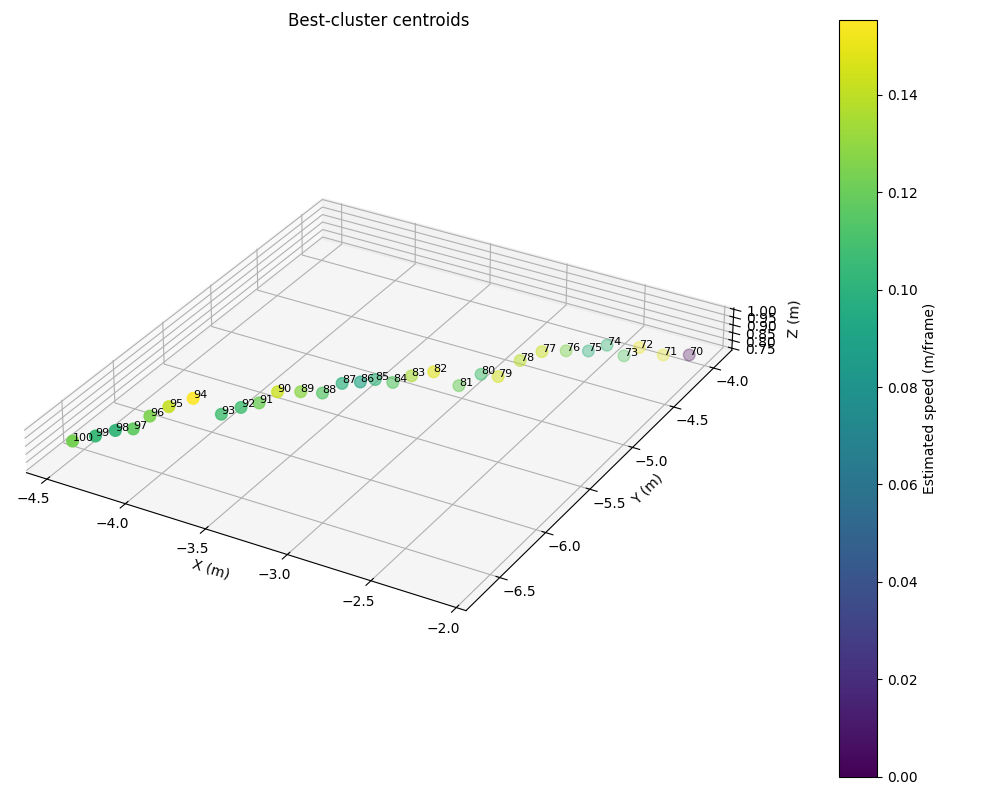

In [12]:
box, settings = _validate_tracking_settings()
selected_frames = frames[:frame_count_widget.value]

centroid_positions = []
centroid_speeds = []
centroid_frame_numbers = []
tracker = None

for frame_number, frame in enumerate(selected_frames, start=FIRST_LOADED_FRAME):
    plot_points = prepare_points(
        frame,
        settings["min_distance"],
        settings["max_distance"],
        settings["keep_fraction"],
        settings["seed"] + frame_number - 1,
    )

    if settings["remove_ground"] and len(plot_points):
        plot_points, _ = remove_ground_plane(
            plot_points,
            settings["ground_distance_threshold"],
            settings["ground_max_iterations"],
            settings["ground_max_tilt_degrees"],
            settings["seed"] + frame_number - 1,
        )

    if not len(plot_points):
        if tracker is not None:
            tracker.predict()
        continue

    labels = cluster_points(
        plot_points,
        method_widget.value,
        cluster_count_widget.value,
        dbscan_eps_widget.value,
        min_samples_widget.value,
        hdbscan_min_cluster_size_widget.value,
        spectral_neighbors_widget.value,
    )
    best = best_cluster_for_box(labels, box_mask(plot_points, box))

    if best is None or not np.any(best["mask"]):
        if tracker is not None:
            tracker.predict()
        continue

    # Centroid of the best cluster for this frame
    centroid = plot_points[best["mask"]].mean(axis=0)

    if tracker is None:
        tracker = ConstantVelocityKalman3D(
            centroid, settings["measurement_noise"], settings["process_noise"]
        )
    else:
        predicted_position = tracker.predict()
        if np.linalg.norm(centroid - predicted_position) <= settings["association_gate"]:
            tracker.update(centroid)

    centroid_positions.append(centroid)
    centroid_speeds.append(float(np.linalg.norm(tracker.state[3:])))
    centroid_frame_numbers.append(frame_number)

if not centroid_positions:
    print("No best-cluster centroids were found for the selected frames.")
else:
    centroid_positions = np.asarray(centroid_positions)
    centroid_speeds = np.asarray(centroid_speeds)

    figure = plt.figure(figsize=(10, 8))
    axes = figure.add_subplot(111, projection="3d")
    points_plot = axes.scatter(
        *centroid_positions.T,
        c=centroid_speeds,
        cmap="viridis",
        s=70,
    )

    for position, frame_number in zip(centroid_positions, centroid_frame_numbers):
        axes.text(*position, str(frame_number), fontsize=8)

    colorbar = figure.colorbar(points_plot, ax=axes, pad=0.1)
    colorbar.set_label("Estimated speed (m/frame)")
    axes.set_title("Best-cluster centroids")
    axes.set_xlabel("X (m)")
    axes.set_ylabel("Y (m)")
    axes.set_zlabel("Z (m)")
    axes.set_box_aspect(np.maximum(np.ptp(centroid_positions, axis=0), 1e-6))
    plt.tight_layout()
    plt.show()

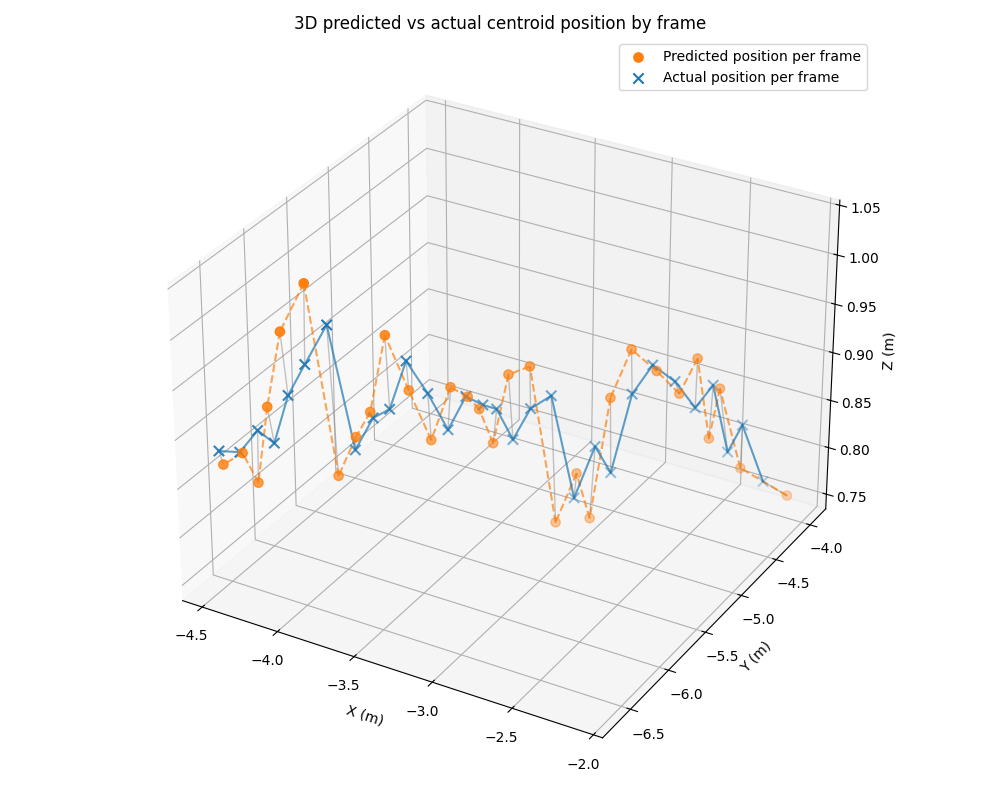

3D comparison shows 30 frame(s); mean predicted-to-actual centroid separation is 0.061 m.


In [18]:
box, settings = _validate_tracking_settings()
comparison_frames = frames[:frame_count_widget.value]
comparison_state = {
    "track_frames": [],
    "prediction_positions": [],
    "detection_positions": [],
}

comparison_tracker = None

for frame_number, raw_frame in enumerate(comparison_frames, start=FIRST_LOADED_FRAME):
    predicted = (
        comparison_tracker.predict()
        if comparison_tracker is not None
        else None
    )
    detection = None

    plot_points = prepare_points(
        raw_frame,
        settings["min_distance"],
        settings["max_distance"],
        settings["keep_fraction"],
        settings["seed"] + frame_number - 1,
    )

    if settings["remove_ground"] and len(plot_points):
        plot_points, _ = remove_ground_plane(
            plot_points,
            settings["ground_distance_threshold"],
            settings["ground_max_iterations"],
            settings["ground_max_tilt_degrees"],
            settings["seed"] + frame_number - 1,
        )

    if len(plot_points):
        labels = cluster_points(
            plot_points,
            method_widget.value,
            cluster_count_widget.value,
            dbscan_eps_widget.value,
            min_samples_widget.value,
            hdbscan_min_cluster_size_widget.value,
            spectral_neighbors_widget.value,
        )
        best = best_cluster_for_box(labels, box_mask(plot_points, box))

        if best is not None and np.any(best["mask"]):
            centroid = plot_points[best["mask"]].mean(axis=0)

            if comparison_tracker is None:
                comparison_tracker = ConstantVelocityKalman3D(
                    centroid,
                    settings["measurement_noise"],
                    settings["process_noise"],
                )
                detection = centroid
            elif np.linalg.norm(centroid - predicted) <= settings["association_gate"]:
                comparison_tracker.update(centroid)
                detection = centroid

    comparison_state["track_frames"].append(frame_number)
    comparison_state["prediction_positions"].append(
        predicted if predicted is not None else np.full(3, np.nan)
    )
    comparison_state["detection_positions"].append(
        detection if detection is not None else np.full(3, np.nan)
    )

_plot_centroid_prediction_comparison(comparison_state)

# Object tracking across all frames

C:\Users\danag\AppData\Local\Temp\ipykernel_18464\312722500.py:140: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  figure, axes = plt.subplots(figsize=(11, 9), subplot_kw={"projection": "3d"})


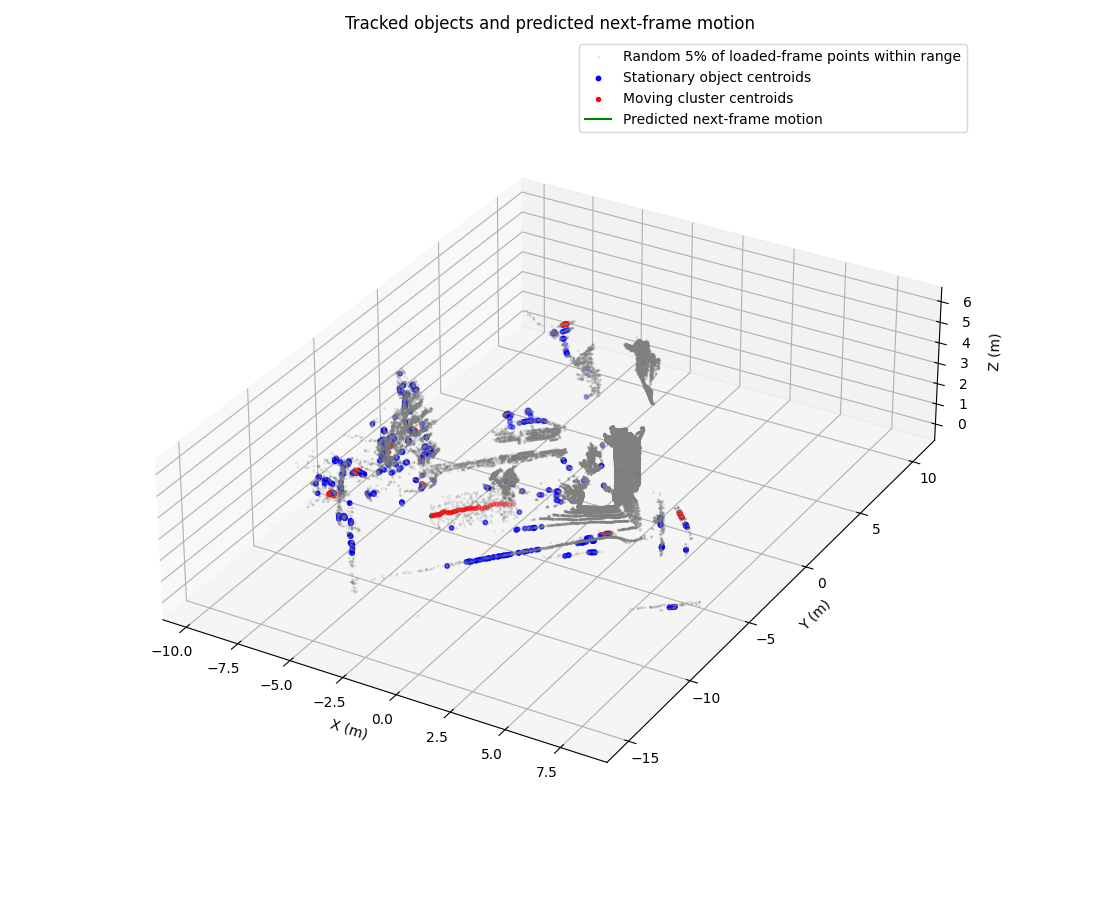

Frames processed: 31
Stationary objects: 551
Moving objects: 16
Moving objects with next-frame predictions: 7
Total tracks: 567


In [33]:
# Re-cluster the loaded recording, associate clusters between consecutive frames
# by nearest centroid, and maintain a Kalman filter for each track.

MOVING_DISPLACEMENT_THRESHOLD_M = 0.1
MIN_TRACK_OBSERVATIONS = 10

association_gate_m = 0.3  #tracking_gate_widget.value
if association_gate_m <= 0:
    raise ValueError("The association gate must be positive.")

object_tracks = {}
previous_frame_centroids = {}
next_object_track_id = 1

for object_frame_number, object_raw_frame in enumerate(
    frames[:frame_count_widget.value],
    start=FIRST_LOADED_FRAME,
):
    object_points = prepare_points(
        object_raw_frame,
        min_distance_widget.value,
        max_distance_widget.value,
        keep_fraction_widget.value,
        random_seed_widget.value + object_frame_number - 1,
    )

    if  ground_removal_widget.value and len(object_points):
        object_points, _ = remove_ground_plane(
            object_points,
            ground_distance_threshold_widget.value,
            ground_ransac_iterations_widget.value,
            ground_max_tilt_widget.value,
            random_seed_widget.value + object_frame_number - 1,
        )

    # Predict each existing Kalman track once per frame.
    predicted_positions = {
        track_id: track_data["filter"].predict()
        for track_id, track_data in object_tracks.items()
    }

    if len(object_points):
        object_labels = cluster_points(
            object_points,
            method_widget.value,
            cluster_count_widget.value,
            0.2,#dbscan_eps_widget.value,
            10,#min_samples_widget.value,
            hdbscan_min_cluster_size_widget.value,
            spectral_neighbors_widget.value,
        )
        current_centroids = cluster_centroids(object_points, object_labels)
    else:
        current_centroids = {}

    # Greedy nearest-centroid matching, as in the notebook's centroid tracker.
    candidate_matches = []
    for track_id, old_centroid in previous_frame_centroids.items():
        for label, centroid in current_centroids.items():
            distance = float(np.linalg.norm(centroid - old_centroid))
            if distance <= association_gate_m:
                candidate_matches.append((distance, track_id, label))

    matched_tracks = {}
    matched_labels = set()
    for _, track_id, label in sorted(candidate_matches):
        if track_id not in matched_tracks.values() and label not in matched_labels:
            matched_tracks[label] = track_id
            matched_labels.add(label)

    new_frame_centroids = {}
    for label, centroid in current_centroids.items():
        if label in matched_tracks:
            track_id = matched_tracks[label]
            track_data = object_tracks[track_id]
            filtered_position = track_data["filter"].update(centroid)
        else:
            track_id = next_object_track_id
            next_object_track_id += 1
            kalman_filter = ConstantVelocityKalman3D(
                centroid,
                tracking_measurement_noise_widget.value,
                tracking_process_noise_widget.value,
            )
            object_tracks[track_id] = {
                "filter": kalman_filter,
                "observed_positions": [],
                "cluster_centroids": [],
                "path": [],
            }
            filtered_position = kalman_filter.state[:3].copy()

        track_data = object_tracks[track_id]
        track_data["observed_positions"].append(filtered_position.copy())
        track_data["cluster_centroids"].append(centroid.copy())
        track_data["path"].append(filtered_position.copy())
        new_frame_centroids[track_id] = centroid.copy()

    # Retain predicted positions in paths when a tracked object is not detected.
    matched_track_ids = set(matched_tracks.values())
    for track_id, predicted_position in predicted_positions.items():
        if track_id not in matched_track_ids:
            object_tracks[track_id]["path"].append(predicted_position.copy())

    previous_frame_centroids = new_frame_centroids


# Classify tracks by their Kalman-filtered displacement between detections.
stationary_tracks = []
moving_tracks = []

for track_id, track_data in object_tracks.items():
    observed = np.asarray(track_data["observed_positions"])
    cluster_centroids_observed = np.asarray(track_data["cluster_centroids"])
    if len(observed) < MIN_TRACK_OBSERVATIONS:
        # Insufficient observations to establish motion: count as stationary.
        stationary_tracks.append((track_id, cluster_centroids_observed.mean(axis=0)))
        continue

    displacement = float(np.linalg.norm(observed[-1] - observed[0]))
    if displacement >= MOVING_DISPLACEMENT_THRESHOLD_M:
        moving_tracks.append((track_id, cluster_centroids_observed))
    else:
        stationary_tracks.append((track_id, cluster_centroids_observed.mean(axis=0)))


last_frame_moving_track_ids = {
    track_id for track_id, _ in moving_tracks
} & set(previous_frame_centroids)
predicted_motion_arrows = []
for track_id in sorted(last_frame_moving_track_ids):
    track_filter = object_tracks[track_id]["filter"]
    current_position = previous_frame_centroids[track_id]
    predicted_next_position = track_filter.state[:3] + track_filter.state[3:]
    if np.all(np.isfinite(current_position)) and np.all(np.isfinite(predicted_next_position)):
        predicted_motion_arrows.append((current_position, predicted_next_position))


# Plot all recording points with tracked stationary centroids and moving-object positions.
figure, axes = plt.subplots(figsize=(11, 9), subplot_kw={"projection": "3d"})

background_point_samples = [
    prepare_points(
        frame[:, :3],
        min_distance_widget.value,
        max_distance_widget.value,
        0.05,
        random_seed_widget.value + frame_index,
    )
    for frame_index, frame in enumerate(frames)
    if len(frame)
]
all_recording_points = (
    np.concatenate(background_point_samples, axis=0)
    if background_point_samples
    else np.empty((0, 3), dtype=float)
)
if len(all_recording_points):
    axes.scatter(
        *all_recording_points.T,
        color="gray",
        alpha=0.15,
        s=1,
        label="Random 5% of loaded-frame points within range",
    )

if stationary_tracks:
    stationary_positions = np.asarray([position for _, position in stationary_tracks])
    axes.scatter(
        *stationary_positions.T,
        color="blue",
        s=10,
        label="Stationary object centroids",
    )

for track_id, centroids in moving_tracks:
    if len(centroids):
        axes.scatter(
            *centroids.T,
            color="red",
            s=8,
            marker="o",
            label="Moving cluster centroids" if track_id == moving_tracks[0][0] else None,
        )

for arrow_index, (current_position, predicted_next_position) in enumerate(predicted_motion_arrows):
    motion_vector = predicted_next_position - current_position
    axes.quiver(
        current_position[0], current_position[1], current_position[2],
        motion_vector[0], motion_vector[1], motion_vector[2],
        color="green",
        arrow_length_ratio=0.25,
        linewidth=1.5,
        label="Predicted next-frame motion" if arrow_index == 0 else None,
    )

axes.set_title("Tracked objects and predicted next-frame motion")
axes.set_xlabel("X (m)")
axes.set_ylabel("Y (m)")
axes.set_zlabel("Z (m)")

all_plot_positions = []
if stationary_tracks:
    all_plot_positions.extend(position for _, position in stationary_tracks)
for _, centroids in moving_tracks:
    all_plot_positions.extend(centroids)
for current_position, predicted_next_position in predicted_motion_arrows:
    all_plot_positions.extend((current_position, predicted_next_position))

if len(all_recording_points):
    plot_minimum = all_recording_points.min(axis=0)
    plot_maximum = all_recording_points.max(axis=0)
    if all_plot_positions:
        tracked_positions = np.asarray(all_plot_positions)
        plot_minimum = np.minimum(plot_minimum, tracked_positions.min(axis=0))
        plot_maximum = np.maximum(plot_maximum, tracked_positions.max(axis=0))
    axes.set_box_aspect(np.maximum(plot_maximum - plot_minimum, 1e-6))
elif all_plot_positions:
    axes.set_box_aspect(np.maximum(np.ptp(np.asarray(all_plot_positions), axis=0), 1e-6))

axes.legend()
plt.tight_layout()
plt.show()

print(f"Frames processed: {min(frame_count_widget.value, len(frames))}")
print(f"Stationary objects: {len(stationary_tracks)}")
print(f"Moving objects: {len(moving_tracks)}")
print(f"Moving objects with next-frame predictions: {len(predicted_motion_arrows)}")
print(f"Total tracks: {len(object_tracks)}")